# Task 3.3 - Clustering       
Goal: Perform K-means clustering (from sratch) to cluster seeds into different goups.         
Deadline: 28th December.     

In [121]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, confusion_matrix, silhouette_score, silhouette_samples
from scipy.optimize import linear_sum_assignment as linear_assignment

Step 1 : Read all the data from the csv file

In [122]:
data = pd.read_csv('seeds_data.csv')
features_names = ['Feature_1','Feature_2','Feature_3','Feature_4','Feature_5','Feature_6','Feature_7']
features = data[features_names].values
labels = data['Class'].values
print(f"Features shape : {features.shape}")
print(f"Labels shape : {labels.shape}")

Features shape : (210, 7)
Labels shape : (210,)


Step 2 : Normalize the features

In [123]:
features = (features - features.mean(axis=0)) / features.std(axis=0)

In [124]:
#function to calculate euclidean distance
def distance(a, b):
    return np.linalg.norm(a - b, axis=1)

In [125]:
def init_kmeans_pp(X, k):
    centroids = [X[np.random.randint(len(X))]]

    for _ in range(1, k):
        distances = np.array([
            min(np.linalg.norm(x - c)**2 for c in centroids)
            for x in X
        ])
        probs = distances / distances.sum()
        cumulative_probs = np.cumsum(probs)
        r = np.random.rand()

        for i, p in enumerate(cumulative_probs):
            if r < p:
                centroids.append(X[i])
                break

    return np.array(centroids)


In [ ]:
#function to perform k-means clustering
def kmeans(X, k, max_iters=1000):
    # Step 1: initialize centroids randomly
    np.random.seed(42)
    indices = np.random.choice(len(X), k, replace=False)
    centroids = X[indices]

    for s in range(max_iters):
        # Step 2: assign clusters
        clusters = [np.argmin([np.linalg.norm(x - c) for c in centroids]) for x in X]

        # Step 3: update centroids
        new_centroids = np.array([X[np.array(clusters) == i].mean(axis=0) for i in range(k)])

        # Stop if converged (no change)
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return np.array(clusters), centroids

Step 3 : Find optimal K using Elbow Method

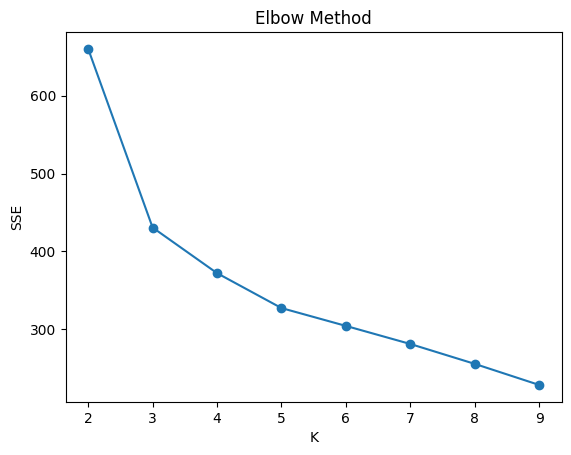

In [127]:
sse = []
K_range = range(2, 10)

for k in K_range:
    clusters, centers = kmeans(features, k)
    sse.append(sum(np.linalg.norm(features[i] - centers[clusters[i]])**2 for i in range(len(features))))

plt.plot(K_range, sse, marker='o')
plt.xlabel("K")
plt.ylabel("SSE")
plt.title("Elbow Method")
plt.show()


Step 4 : Perform K-means clustering using optimal k(=3) and find Cluster Centers

In [ ]:
k_optimal = 3  # based on elbow
clusters, centers = kmeans(features, k_optimal)

print("\nCluster Centers:")
print(pd.DataFrame(centers))


Cluster Centers:
          0         1         2         3         4         5         6
0 -1.030253 -1.006649 -0.964905 -0.897685 -1.085583  0.694804 -0.624809
1  1.256682  1.261966  0.560464  1.237883  1.164852 -0.045219  1.292308
2 -0.141119 -0.170043  0.449606 -0.257814  0.001647 -0.661919 -0.585893


Step 5 : Use PCA to visualize the clusters

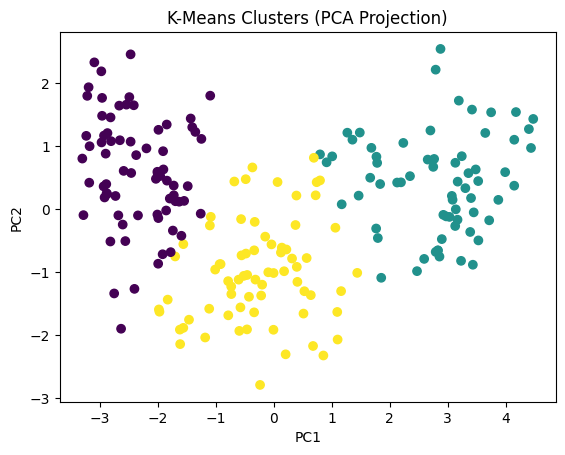

In [130]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(features)

plt.scatter(X_2d[:,0], X_2d[:,1], c=clusters, cmap="viridis")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("K-Means Clusters (PCA Projection)")
plt.show()

Step 6: Compare performance using metrics like ARI, confusion matrix and silhouette score

In [131]:
# Map cluster labels to actual labels
mapping = {}
for cluster in range(k_optimal):
    mask = (clusters == cluster)
    true_labels = labels[mask]
    if len(true_labels) > 0:
        mapping[cluster] = np.bincount(true_labels).argmax()

# Create new predicted labels aligned with true classes
aligned_preds = np.vectorize(mapping.get)(clusters)

print("ARI:", adjusted_rand_score(labels, aligned_preds))
print("Confusion Matrix:\n", confusion_matrix(labels, aligned_preds))

ARI: 0.7732937360806309
Confusion Matrix:
 [[62  2  6]
 [ 5 65  0]
 [ 4  0 66]]


In [132]:
sil_score = silhouette_score(features, clusters)
print("Silhouette Score:", sil_score)

sil_samples = silhouette_samples(features, clusters)
print("Mean silhouette:", sil_samples.mean())
print("Min silhouette:", sil_samples.min())

Silhouette Score: 0.40072705527512986
Mean silhouette: 0.40072705527512986
Min silhouette: 0.00271308934767822


High ARI of 0.823 tells us that clustering aligns well with ground true labels, while a moderate silhouette score of 0.404 indicates that despite correct grouping, there is some overlap in feature space, making geometric separation imperfect

In [133]:
def init_kmeans_pp(X, k):
    centroids = [X[np.random.randint(len(X))]]

    for _ in range(1, k):
        distances = np.array([
            min(np.linalg.norm(x - c)**2 for c in centroids)
            for x in X
        ])
        probs = distances / distances.sum()
        cumulative_probs = np.cumsum(probs)
        r = np.random.rand()

        for i, p in enumerate(cumulative_probs):
            if r < p:
                centroids.append(X[i])
                break

    return np.array(centroids)


In [134]:
#function to perform k-means clustering
def kmeans(X, k, max_iters=1000):
    # Step 1: initialize centroids 
    centroids = init_kmeans_pp(X, k)

    for s in range(max_iters):
        # Step 2: assign clusters
        clusters = [np.argmin([np.linalg.norm(x - c) for c in centroids]) for x in X]

        # Step 3: update centroids
        new_centroids = np.array([X[np.array(clusters) == i].mean(axis=0) for i in range(k)])

        # Stop if converged (no change)
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return np.array(clusters), centroids

In [135]:
def kmeans_best_of_n(X, k, n_runs=100):
    best_sse = np.inf
    best_clusters, best_centers = None, None

    for _ in range(n_runs):
        clusters, centers = kmeans(X, k)
        sse = sum(np.linalg.norm(X[i] - centers[clusters[i]])**2 for i in range(len(X)))

        if sse < best_sse:
            best_sse = sse
            best_clusters, best_centers = clusters, centers

    return best_clusters, best_centers

In [136]:
k_optimal = 3  # based on elbow
clusters, centers = kmeans_best_of_n(features, 3)

print("\nCluster Centers:")
print(pd.DataFrame(centers))


Cluster Centers:
          0         1         2         3         4         5         6
0 -1.030253 -1.006649 -0.964905 -0.897685 -1.085583  0.694804 -0.624809
1 -0.141119 -0.170043  0.449606 -0.257814  0.001647 -0.661919 -0.585893
2  1.256682  1.261966  0.560464  1.237883  1.164852 -0.045219  1.292308


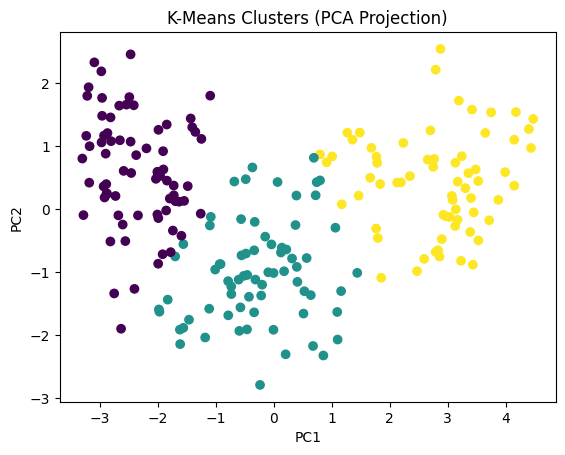

In [137]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(features)

plt.scatter(X_2d[:,0], X_2d[:,1], c=clusters, cmap="viridis")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("K-Means Clusters (PCA Projection)")
plt.show()

In [138]:
# Map cluster labels to actual labels
mapping = {}
for cluster in range(k_optimal):
    mask = (clusters == cluster)
    true_labels = labels[mask]
    if len(true_labels) > 0:
        mapping[cluster] = np.bincount(true_labels).argmax()

# Create new predicted labels aligned with true classes
aligned_preds = np.vectorize(mapping.get)(clusters)

print("ARI:", adjusted_rand_score(labels, aligned_preds))
print("Confusion Matrix:\n", confusion_matrix(labels, aligned_preds))

ARI: 0.7732937360806309
Confusion Matrix:
 [[62  2  6]
 [ 5 65  0]
 [ 4  0 66]]


In [139]:
sil_score = silhouette_score(features, clusters)
print("Silhouette Score:", sil_score)

sil_samples = silhouette_samples(features, clusters)
print("Mean silhouette:", sil_samples.mean())
print("Min silhouette:", sil_samples.min())

Silhouette Score: 0.40072705527512986
Mean silhouette: 0.40072705527512986
Min silhouette: 0.00271308934767822
